## 1. Import Required Libraries
We use Pandas and NumPy for data handling, Matplotlib for plots, Scikit-learn for preprocessing and evaluation, and TensorFlow/Keras to build the neural network.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

# Keep results reproducible
np.random.seed(42)
tf.random.set_seed(42)

## 2. Create the Gaming Industry Dataset
The dataset contains game information and market signals. The target column, `Demand_Units`, represents the simulated number of units demanded.

In [6]:
n = 1000

genres = np.random.choice(['Action', 'Sports', 'RPG', 'Simulation', 'Puzzle'], n)
platforms = np.random.choice(['PC', 'PlayStation', 'Xbox', 'Mobile'], n)
months = np.random.choice(
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], n
)

price = np.random.uniform(5, 80, n).round(2)
marketing_budget = np.random.uniform(10, 150, n).round(1)  # thousand USD
social_buzz = np.random.randint(0, 101, n)
pre_orders = np.random.randint(100, 10001, n)
user_rating = np.random.uniform(2.5, 5.0, n).round(1)
discount = np.random.randint(0, 51, n)

# Simple effects used to create realistic-looking example demand values
genre_effect = {'Action': 1300, 'Sports': 900, 'RPG': 1100, 'Simulation': 500, 'Puzzle': 300}
platform_effect = {'PC': 200, 'PlayStation': 600, 'Xbox': 300, 'Mobile': 400}
month_effect = {
    'Jan': 0, 'Feb': -100, 'Mar': 100, 'Apr': 0, 'May': 100, 'Jun': 250,
    'Jul': 150, 'Aug': 100, 'Sep': 200, 'Oct': 700, 'Nov': 1100, 'Dec': 1300
}

base_demand = (
    900
    + 0.85 * pre_orders
    + 18 * marketing_budget
    + 15 * social_buzz
    + 500 * (user_rating - 3.5)
    - 18 * price
    + 20 * discount
    + np.array([genre_effect[x] for x in genres])
    + np.array([platform_effect[x] for x in platforms])
    + np.array([month_effect[x] for x in months])
)

demand = np.maximum(100, base_demand + np.random.normal(0, 450, n)).astype(int)

data = pd.DataFrame({
    'Genre': genres,
    'Platform': platforms,
    'Month': months,
    'Price_USD': price,
    'Marketing_Budget_Thousand_USD': marketing_budget,
    'Social_Media_Buzz': social_buzz,
    'Pre_Orders': pre_orders,
    'User_Rating': user_rating,
    'Discount_Percent': discount,
    'Demand_Units': demand
})

# Display the first five records
data.head()

,Genre,Platform,Month,Price_USD,Marketing_Budget_Thousand_USD,Social_Media_Buzz,Pre_Orders,User_Rating,Discount_Percent,Demand_Units
0,Simulation,Mobile,Jul,52.82,58.2,81,1229,4.0,45,5350
1,Puzzle,Mobile,Dec,42.21,14.3,53,1705,4.3,16,5515
2,RPG,Mobile,Jan,18.37,17.3,74,3033,3.4,41,6447
3,Puzzle,Mobile,Aug,56.44,29.9,15,9507,2.7,11,9841
4,Puzzle,Mobile,Nov,79.33,39.9,17,8616,3.6,47,10753


## 3. Explore the Dataset
Check the dataset size, column types, and average demand.

In [7]:
print('Dataset shape:', data.shape)
print('\nColumn information:')
data.info()
print('\nAverage demand:', round(data['Demand_Units'].mean(), 0), 'units')

# View basic statistics for numeric columns
data.select_dtypes(include=[np.number]).describe()

Dataset shape: (1000, 10)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Genre                          1000 non-null   object 
 1   Platform                       1000 non-null   object 
 2   Month                          1000 non-null   object 
 3   Price_USD                      1000 non-null   float64
 4   Marketing_Budget_Thousand_USD  1000 non-null   float64
 5   Social_Media_Buzz              1000 non-null   int64  
 6   Pre_Orders                     1000 non-null   int64  
 7   User_Rating                    1000 non-null   float64
 8   Discount_Percent               1000 non-null   int64  
 9   Demand_Units                   1000 non-null   int64  
dtypes: float64(3), int64(4), object(3)
memory usage: 78.3+ KB

Average demand: 8686.0 units


,Price_USD,Marketing_Budget_Thousand_USD,Social_Media_Buzz,Pre_Orders,User_Rating,Discount_Percent,Demand_Units
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000,1000.000000
mean,43.074380,81.243100,49.207000,5009.62200,3.738100,24.02600,8685.721000
std,21.926566,39.767302,28.919137,2816.48152,0.724115,14.56274,2722.093879
min,5.010000,10.300000,0.000000,101.00000,2.500000,0.00000,1092.000000
25%,24.047500,48.150000,24.000000,2702.50000,3.100000,11.00000,6629.750000
50%,44.290000,82.150000,47.500000,5030.00000,3.700000,23.00000,8787.500000
75%,62.095000,115.500000,75.000000,7412.75000,4.400000,37.00000,10748.500000
max,79.980000,149.700000,100.000000,9936.00000,5.000000,50.00000,15643.000000


## 4. Prepare the Data
Convert text categories into numeric columns using one-hot encoding. Split the data into training and testing sets, then scale the inputs.

In [8]:
X = data.drop('Demand_Units', axis=1)
y = data['Demand_Units']

# Convert Genre, Platform and Month into numeric indicator columns
X = pd.get_dummies(X, columns=['Genre', 'Platform', 'Month'], dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Fit scaling only on the training data to avoid data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Training records:', X_train.shape[0])
print('Testing records:', X_test.shape[0])
print('Number of input features:', X_train.shape[1])

Training records: 800
Testing records: 200
Number of input features: 27


## 5. Build the Neural Network Model
The model has an input layer, two hidden layers with ReLU activation, and one output neuron to predict demand.

In [9]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)  # One numeric output: predicted demand
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mean_absolute_error']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,905 (15.25 KB)

 Trainable params: 3,905 (15.25 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the Model
Train the network for 50 epochs. A validation split is used to monitor performance during training.

In [10]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 83705904.0000 - mean_absolute_error: 8722.3799 - val_loss: 79994224.0000 - val_mean_absolute_error: 8602.6514
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 83672976.0000 - mean_absolute_error: 8720.4658 - val_loss: 79957776.0000 - val_mean_absolute_error: 8600.5205
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 83627224.0000 - mean_absolute_error: 8717.8408 - val_loss: 79903600.0000 - val_mean_absolute_error: 8597.3809
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 83556880.0000 - mean_absolute_error: 8713.8730 - val_loss: 79821272.0000 - val_mean_absolute_error: 8592.6719
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 83450984.0000 - mean_absolute_error: 8707.9873 - val_loss: 79701064.0000 - val_mean_absolute_error: 8585.8623
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 83297496.0000 - mean_absolute_error: 8699.5557 - val_loss: 79532144.0000 - val_mean_absolute_error: 8

## 7. Plot Training and Validation Loss
A decreasing loss generally indicates that the model is learning from the data.

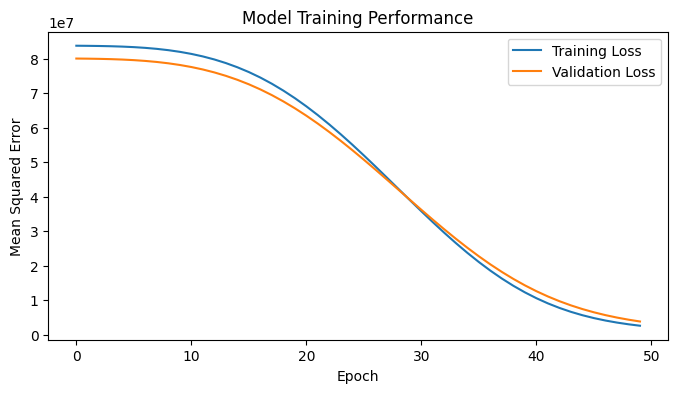

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('Model Training Performance')
plt.legend()
plt.show()

## 8. Evaluate the Model
Use the testing data to calculate MAE, RMSE and R² score. Lower MAE/RMSE and an R² closer to 1 indicate better predictions.

In [12]:
predictions = model.predict(X_test_scaled).flatten()

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print('Mean Absolute Error (MAE):', round(mae, 2), 'units')
print('Root Mean Squared Error (RMSE):', round(rmse, 2), 'units')
print('R² Score:', round(r2, 3))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
Mean Absolute Error (MAE): 1491.11 units
Root Mean Squared Error (RMSE): 1779.25 units
R² Score: 0.595


## 9. Compare Actual and Predicted Demand
View a few predictions from the test set.

In [13]:
comparison = pd.DataFrame({
    'Actual_Demand': y_test.values,
    'Predicted_Demand': np.round(predictions).astype(int)
})
comparison.head(10)

,Actual_Demand,Predicted_Demand
0,11146,11266
1,12746,11503
2,7064,5021
3,7224,5359
4,10911,8796
5,5564,5191
6,3535,4403
7,8582,8207
8,10325,8770
9,12271,10905


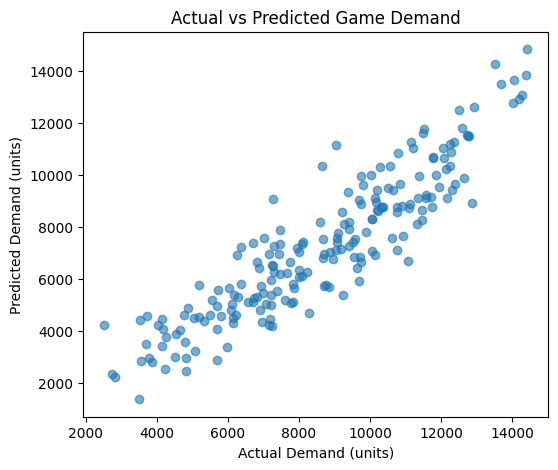

In [14]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, predictions, alpha=0.6)
plt.xlabel('Actual Demand (units)')
plt.ylabel('Predicted Demand (units)')
plt.title('Actual vs Predicted Game Demand')
plt.show()

## 10. Predict Demand for a New Game
Enter sample information for a new game. The trained model will estimate its demand.

In [15]:
new_game = pd.DataFrame([{
    'Genre': 'Action',
    'Platform': 'PlayStation',
    'Month': 'Nov',
    'Price_USD': 49.99,
    'Marketing_Budget_Thousand_USD': 100,
    'Social_Media_Buzz': 85,
    'Pre_Orders': 7000,
    'User_Rating': 4.5,
    'Discount_Percent': 10
}])

# Apply the same one-hot columns and scaling used during training
new_game_encoded = pd.get_dummies(new_game, columns=['Genre', 'Platform', 'Month'], dtype=int)
new_game_encoded = new_game_encoded.reindex(columns=X.columns, fill_value=0)
new_game_scaled = scaler.transform(new_game_encoded)

predicted_demand = model.predict(new_game_scaled)[0][0]
print('Estimated demand for the new game:', round(max(0, predicted_demand)), 'units')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Estimated demand for the new game: 11780 units


## Outcome
A simple Artificial Neural Network was created and trained to estimate video game demand. The model was evaluated using MAE, RMSE and R² score, and was also used to predict demand for a new game.

## Conclusion
The project demonstrates how deep learning can be applied to the gaming industry. Factors such as genre, platform, price, marketing, pre-orders, ratings and launch month can help estimate demand. The example uses generated data, so real business decisions would require a reliable dataset of actual game sales and market activity.